# **Dulce Cristina Rodríguez Rodríguez**
## **Diplomado de programación en python para la web y análisis de datos**
### **Portafolio de evidencias de aprendizaje**
**Introducción:** El presente notebook desarrolla un modelo de clasificación mediante la metodología CRISP-DM, utilizando resultados históricos de partidos internacionales de fútbol. Se realizan las etapas de comprensión del negocio, preparación de datos, modelado y evaluación para clasificar los encuentros en amistosos y no amistosos.


# Notebook 2. Proyecto completo de clasificación mediante CRISP-DM

**Problema:** clasificar partidos internacionales de fútbol como *Amistoso* o *No amistoso* usando resultados históricos.

**Objetivo:** desarrollar un flujo completo de clasificación con Python y Scikit-learn, documentando las cinco fases de CRISP-DM.

**Dataset:** `results.csv`, con registros históricos de partidos internacionales.

> **Consideración metodológica:** la etiqueta `tipo_partido` se construye a partir de `tournament`. Por ello, `tournament` se excluye de los predictores para evitar revelar directamente la respuesta al modelo. También se excluyen los goles, porque se conocen después del partido y producirían fuga de información si la clasificación se pretende hacer antes del encuentro. Las variables de sede y equipos pueden no ser suficientes para predecir el tipo de competición; esta limitación se analizará en las conclusiones.

**Entorno:** Google Colab o Jupyter. En Colab, carga `results.csv` en la sesión o ajusta la ruta del archivo.

## Importación de bibliotecas y carga de datos

Se utilizan Pandas y NumPy para manipulación de datos, Matplotlib y Seaborn para visualizaciones, y Scikit-learn para preparar, entrenar y evaluar el modelo.

In [ ]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RUTA_DATASET = "/content/results.csv"

# Si no estás en Google Colab, cambia RUTA_DATASET por la ruta local del CSV.
if not os.path.exists(RUTA_DATASET):
    RUTA_DATASET = "results.csv"

if not os.path.exists(RUTA_DATASET):
    raise FileNotFoundError(
        "No se encontró results.csv. Carga el archivo en Colab o actualiza RUTA_DATASET."
    )

df_original = pd.read_csv(RUTA_DATASET)
print(f"Dataset cargado correctamente: {df_original.shape[0]:,} registros y "
      f"{df_original.shape[1]} columnas.")
display(df_original.head())

Dataset cargado correctamente: 41,243 registros y 9 columnas.


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False


# Fase 1. Comprensión del negocio (Business Understanding)

## 1.1 Descripción y justificación del problema

El conjunto de datos contiene resultados históricos de partidos internacionales de fútbol. El proyecto plantea construir un clasificador que distinga entre partidos amistosos y no amistosos a partir de información disponible sobre los equipos y la sede.

## 1.2 Objetivo del proyecto

Entrenar y evaluar un modelo de aprendizaje automático que clasifique cada registro en una de dos categorías: **Amistoso** o **No amistoso**.

## 1.3 Variable objetivo

Se crea `tipo_partido` a partir de `tournament`:
- `Amistoso`: cuando el torneo es `Friendly` (ignorando mayúsculas y espacios).
- `No amistoso`: para los demás valores.

## 1.4 Resultados esperados

- Un conjunto de datos preparado para el modelado.
- Un modelo de clasificación entrenado.
- Predicciones para registros reservados para prueba.
- Métricas y matriz de confusión.
- Una conclusión sobre el desempeño, las limitaciones y las mejoras posibles.

## 1.5 Criterios de éxito

El modelo se eveluá con accuracy, precision, recall y F1-score, además de la matriz de confusión, y se analizá si el desempeño resulta útil para el propósito planteado.

Distribución de la variable objetivo:


,Cantidad,Porcentaje
Clase,,
No amistoso,24232,58.75
Amistoso,17011,41.25


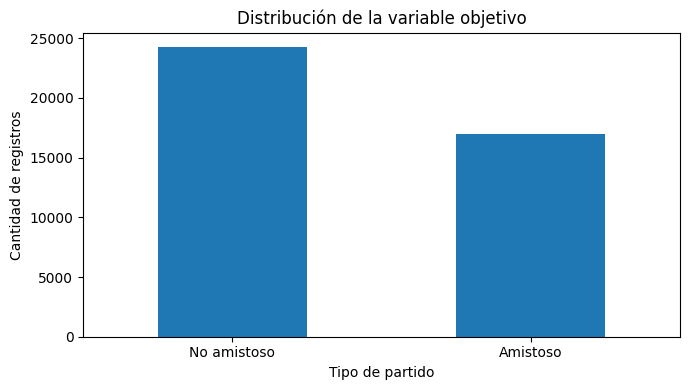

In [ ]:
# Verificar las columnas mínimas requeridas y crear la variable objetivo.
if "tournament" not in df_original.columns:
    raise ValueError("El archivo debe contener una columna llamada 'tournament'.")

df = df_original.copy()
torneo = df["tournament"].astype("string").str.strip()
df["tipo_partido"] = np.where(
    torneo.str.casefold().eq("friendly").fillna(False),
    "Amistoso",
    "No amistoso"
)

print("Distribución de la variable objetivo:")
display(
    df["tipo_partido"].value_counts()
      .rename_axis("Clase")
      .to_frame("Cantidad")
      .assign(Porcentaje=lambda x: (x["Cantidad"] / len(df) * 100).round(2))
)

ax = df["tipo_partido"].value_counts().plot(kind="bar", figsize=(7, 4))
ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel("Tipo de partido")
ax.set_ylabel("Cantidad de registros")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Fase 2. Comprensión de los datos (Data Understanding)

En esta fase se revisan las dimensiones, los tipos de datos, los faltantes, los duplicados, las estadísticas descriptivas y la distribución de las variables. Las decisiones de limpieza se ejecutarán en la Fase 3, para mantener separadas la exploración y la preparación.

In [ ]:
print("Dimensiones:", df.shape)
print("\\nColumnas:")
print(df.columns.tolist())
print("\\nInformación general:")
df.info()

print("\\nValores faltantes por variable:")
faltantes = pd.DataFrame({
    "Cantidad": df.isna().sum(),
    "Porcentaje": (df.isna().mean() * 100).round(2)
}).sort_values("Cantidad", ascending=False)
display(faltantes)

print("Registros completamente duplicados:", int(df.duplicated().sum()))

print("\\nEstadísticas descriptivas numéricas:")
display(df.select_dtypes(include=np.number).describe().T)

print("\\nEstadísticas descriptivas categóricas:")
display(df.select_dtypes(include=["object", "category", "bool", "string"]).describe().T)

Dimensiones: (41243, 10)
\nColumnas:
['date', 'home_team', 'away_team', 'home_score', 'away_score', 'tournament', 'city', 'country', 'neutral', 'tipo_partido']
\nInformación general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41243 entries, 0 to 41242
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   date          41243 non-null  object
 1   home_team     41243 non-null  object
 2   away_team     41243 non-null  object
 3   home_score    41243 non-null  int64 
 4   away_score    41243 non-null  int64 
 5   tournament    41243 non-null  object
 6   city          41243 non-null  object
 7   country       41243 non-null  object
 8   neutral       41243 non-null  bool  
 9   tipo_partido  41243 non-null  object
dtypes: bool(1), int64(2), object(7)
memory usage: 2.9+ MB
\nValores faltantes por variable:


,Cantidad,Porcentaje
date,0,0.0
home_team,0,0.0
away_team,0,0.0
home_score,0,0.0
away_score,0,0.0
tournament,0,0.0
city,0,0.0
country,0,0.0
neutral,0,0.0
tipo_partido,0,0.0


Registros completamente duplicados: 0
\nEstadísticas descriptivas numéricas:


,count,mean,std,min,25%,50%,75%,max
home_score,41243.0,1.744975,1.750513,0.0,1.0,1.0,2.0,31.0
away_score,41243.0,1.189317,1.406648,0.0,0.0,1.0,2.0,21.0


\nEstadísticas descriptivas categóricas:


,count,unique,top,freq
date,41243,15154,2012-02-29,66
home_team,41243,310,Brazil,567
away_team,41243,307,Uruguay,539
tournament,41243,112,Friendly,17011
city,41243,2002,Kuala Lumpur,583
country,41243,266,United States,1154
neutral,41243,2,False,31015
tipo_partido,41243,2,No amistoso,24232


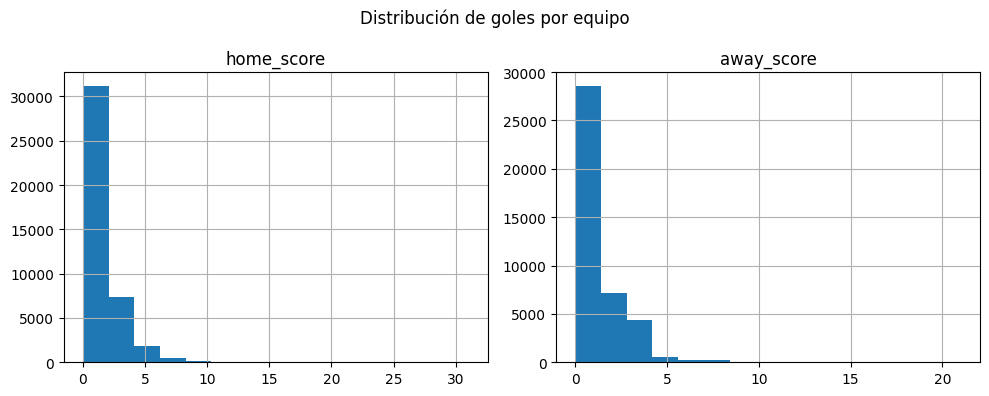

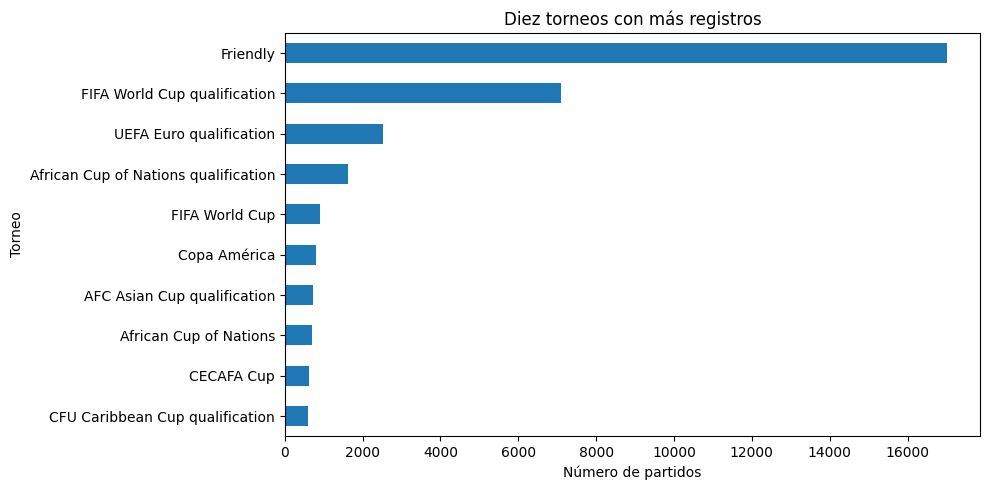

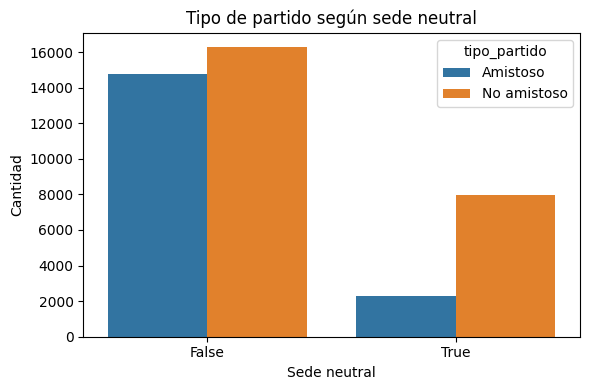

,count,mean,median,std
tipo_partido,,,,
Amistoso,17011,2.90,3.0,2.03
No amistoso,24232,2.96,3.0,2.14


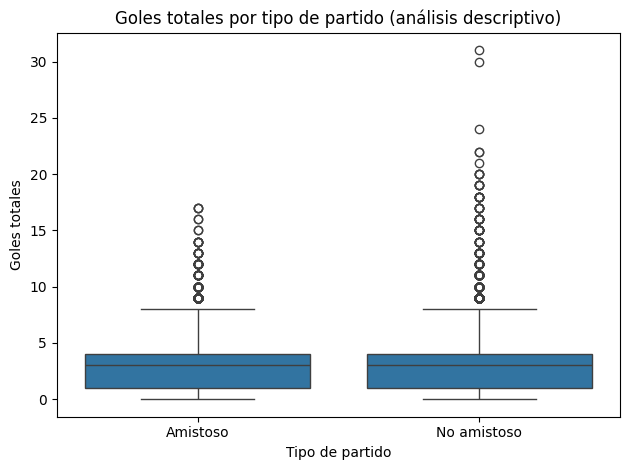

In [ ]:
# Visualizaciones exploratorias: distribución de goles y categorías frecuentes.
columnas_goles = [c for c in ["home_score", "away_score"] if c in df.columns]
if columnas_goles:
    df[columnas_goles].apply(pd.to_numeric, errors="coerce").hist(
        figsize=(10, 4), bins=15
    )
    plt.suptitle("Distribución de goles por equipo")
    plt.tight_layout()
    plt.show()

if "tournament" in df.columns:
    plt.figure(figsize=(10, 5))
    df["tournament"].value_counts().head(10).sort_values().plot(kind="barh")
    plt.title("Diez torneos con más registros")
    plt.xlabel("Número de partidos")
    plt.ylabel("Torneo")
    plt.tight_layout()
    plt.show()

if "neutral" in df.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x="neutral", hue="tipo_partido")
    plt.title("Tipo de partido según sede neutral")
    plt.xlabel("Sede neutral")
    plt.ylabel("Cantidad")
    plt.tight_layout()
    plt.show()

if {"home_score", "away_score"}.issubset(df.columns):
    goles = (pd.to_numeric(df["home_score"], errors="coerce") +
             pd.to_numeric(df["away_score"], errors="coerce"))
    resumen = pd.DataFrame({"tipo_partido": df["tipo_partido"], "goles_totales": goles})
    display(resumen.groupby("tipo_partido")["goles_totales"].agg(
        ["count", "mean", "median", "std"]
    ).round(2))
    sns.boxplot(data=resumen, x="tipo_partido", y="goles_totales")
    plt.title("Goles totales por tipo de partido (análisis descriptivo)")
    plt.xlabel("Tipo de partido")
    plt.ylabel("Goles totales")
    plt.tight_layout()
    plt.show()

## 2.1 Interpretación inicial
- La asociación entre sede neutral y tipo de partido no implica causalidad.
- `tournament` define la etiqueta y no debe formar parte de las variables de entrada.

# Fase 3. Preparación de los datos (Data Preparation)

se eliminan duplicados y se excluye  `tournament` (origen de la etiqueta), los marcadores de goles: `home_score`, `away_score`, `winner`, `result`.

La codificación categórica y la imputación se implementan dentro de un `Pipeline`. Esto permite ajustar las transformaciones únicamente con los datos de entrenamiento y reduce el riesgo de fuga de información.

In [ ]:
# 3.1 Eliminar duplicados exactos
n_antes = len(df)
df_modelo = df.drop_duplicates().copy()
print(f"Duplicados eliminados: {n_antes - len(df_modelo)}")

# 3.2 Ingeniería simple de fecha: año, mes y día de la semana.
if "date" in df_modelo.columns:
    fecha = pd.to_datetime(df_modelo["date"], errors="coerce")
    df_modelo["fecha_anio"] = fecha.dt.year
    df_modelo["fecha_mes"] = fecha.dt.month
    df_modelo["fecha_dia_semana"] = fecha.dt.dayofweek
    df_modelo = df_modelo.drop(columns=["date"])

# 3.3 Reconstruir la etiqueta tras la eliminación de duplicados.
torneo_limpio = df_modelo["tournament"].astype("string").str.strip()
y = np.where(
    torneo_limpio.str.casefold().eq("friendly").fillna(False),
    "Amistoso",
    "No amistoso"
)
y = pd.Series(y, index=df_modelo.index, name="tipo_partido")

# 3.4 Selección de variables predictoras: excluir etiqueta y variables con fuga.
columnas_excluir = {
    "tournament", "tipo_partido", "home_score", "away_score",
    "winner", "result", "home_team_score", "away_team_score"
}
X = df_modelo.drop(
    columns=[c for c in columnas_excluir if c in df_modelo.columns],
    errors="ignore"
)

# Excluir columnas que estén totalmente vacías y columnas constantes.
X = X.dropna(axis=1, how="all")
X = X.loc[:, X.nunique(dropna=False) > 1]

# Convertir booleanos a texto/categoría para codificarlos de manera consistente.
for col in X.select_dtypes(include="bool").columns:
    X[col] = X[col].astype("string")

print("Variables predictoras seleccionadas:")
print(X.columns.tolist())
print("Dimensiones de X:", X.shape)
print("Distribución de y:")
display(y.value_counts().to_frame("Cantidad"))

Duplicados eliminados: 0
Variables predictoras seleccionadas:
['home_team', 'away_team', 'city', 'country', 'neutral', 'fecha_anio', 'fecha_mes', 'fecha_dia_semana']
Dimensiones de X: (41243, 8)
Distribución de y:


,Cantidad
tipo_partido,
No amistoso,24232
Amistoso,17011


In [ ]:
# 3.5 Separación entrenamiento/prueba con estratificación.
# Si alguna clase tiene menos de dos observaciones, se detiene con un mensaje claro.
conteos = y.value_counts()
if len(conteos) < 2:
    raise ValueError("La variable objetivo solo contiene una clase; no es posible entrenar clasificación.")
if conteos.min() < 2:
    raise ValueError(
        "Una clase tiene menos de dos registros. Se necesitan más ejemplos por clase "
        "para crear conjuntos de entrenamiento y prueba estratificados."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))
print("\\nDistribución porcentual en entrenamiento:")
display((y_train.value_counts(normalize=True) * 100).round(2).to_frame("Porcentaje"))
print("\\nDistribución porcentual en prueba:")
display((y_test.value_counts(normalize=True) * 100).round(2).to_frame("Porcentaje"))

# Identificar variables por tipo
columnas_numericas = X_train.select_dtypes(include=np.number).columns.tolist()
columnas_categoricas = [c for c in X_train.columns if c not in columnas_numericas]

transformadores = []
if columnas_numericas:
    pipeline_numerico = Pipeline(steps=[
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler())
    ])
    transformadores.append(("numericas", pipeline_numerico, columnas_numericas))

if columnas_categoricas:
    pipeline_categorico = Pipeline(steps=[
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OneHotEncoder(handle_unknown="ignore"))
    ])
    transformadores.append(("categoricas", pipeline_categorico, columnas_categoricas))

preprocesador = ColumnTransformer(
    transformers=transformadores,
    remainder="drop"
)

print("Variables numéricas:", columnas_numericas)
print("Variables categóricas:", columnas_categoricas)

Registros de entrenamiento: 32994
Registros de prueba: 8249
\nDistribución porcentual en entrenamiento:


,Porcentaje
tipo_partido,
No amistoso,58.75
Amistoso,41.25


\nDistribución porcentual en prueba:


,Porcentaje
tipo_partido,
No amistoso,58.76
Amistoso,41.24


Variables numéricas: ['fecha_anio', 'fecha_mes', 'fecha_dia_semana']
Variables categóricas: ['home_team', 'away_team', 'city', 'country', 'neutral']


## Explicación de la preparación

- **Duplicados:** se eliminan las filas completamente repetidas.
- **Valores faltantes numéricos:** se imputan con la mediana calculada sobre entrenamiento.
- **Valores faltantes categóricos:** se imputan con la categoría más frecuente calculada sobre entrenamiento.
- **Variables categóricas:** se convierten a columnas binarias mediante One-Hot Encoding.
- **Estandarización:** se aplica a las variables numéricas para ponerlas en escalas comparables.
- **Separación de datos:** el 80 % se utiliza para entrenar y el 20 % para evaluar. `random_state=42` permite reproducir la división.
- **Prevención de fuga:** las transformaciones se ajustan dentro del pipeline y solo con el conjunto de entrenamiento.

# Fase 4. Modelado (Modeling)

Se usa la **Regresión Logística**, un algoritmo de clasificación que estima la probabilidad de pertenecer a cada clase a partir de una combinación ponderada de las variables de entrada. Aunque su nombre incluye “regresión”, también se utiliza para clasificación.

In [ ]:
modelo = Pipeline(steps=[
    ("preparacion", preprocesador),
    ("clasificador", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

modelo.fit(X_train, y_train)
print("Modelo entrenado correctamente.")

# Predicciones sobre datos no usados durante el entrenamiento.
y_pred = modelo.predict(X_test)

predicciones = pd.DataFrame({
    "Clase_real": y_test,
    "Clase_predicha": y_pred
}, index=y_test.index)

print("\\nEjemplos de predicciones:")
display(predicciones.head(15))

Modelo entrenado correctamente.
\nEjemplos de predicciones:


,Clase_real,Clase_predicha
33855,Amistoso,No amistoso
38457,No amistoso,No amistoso
24773,No amistoso,No amistoso
3240,Amistoso,Amistoso
24250,No amistoso,No amistoso
17598,No amistoso,No amistoso
36337,No amistoso,No amistoso
4129,No amistoso,Amistoso
31295,No amistoso,No amistoso
25681,No amistoso,No amistoso


## 4.1 ¿Cómo funciona el algoritmo?

La Regresión Logística combina las variables predictoras y calcula una probabilidad para cada clase. En clasificación binaria, esa probabilidad se convierte en una etiqueta usando un umbral de decisión. El modelo aprende sus coeficientes a partir de los registros de entrenamiento.

Se utiliza `class_weight="balanced"` para ponderar las clases de forma inversamente proporcional a su frecuencia durante el entrenamiento. Esto puede ayudar cuando existe desequilibrio, aunque no garantiza un mejor resultado en todas las métricas.

# Fase 5. Evaluación (Evaluation)

Se calcula el accuracy, precision, recall y F1-score, además de una matriz de confusión. Para precisión, recall y F1 se utiliza el promedio macro, que calcula la métrica por clase y luego promedia ambas clases con el mismo peso. Esto permite observar mejor el desempeño cuando las clases tienen tamaños diferentes.

,Métrica,Valor
0,Accuracy,0.7121
1,Precision macro,0.7082
2,Recall macro,0.7143
3,F1-score macro,0.7084


Reporte de clasificación:
              precision    recall  f1-score   support

    Amistoso       0.63      0.73      0.68      3402
 No amistoso       0.79      0.70      0.74      4847

    accuracy                           0.71      8249
   macro avg       0.71      0.71      0.71      8249
weighted avg       0.72      0.71      0.71      8249



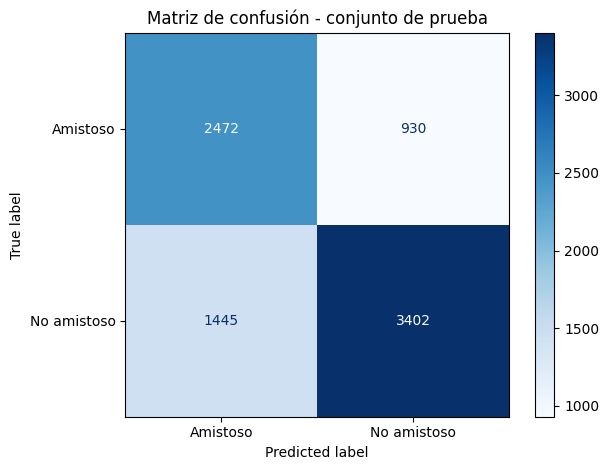

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)

metricas = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision macro", "Recall macro", "F1-score macro"],
    "Valor": [accuracy, precision_macro, recall_macro, f1_macro]
})
metricas["Valor"] = metricas["Valor"].round(4)
display(metricas)

print("Reporte de clasificación:")
print(classification_report(y_test, y_pred, zero_division=0))

etiquetas = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=etiquetas)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=etiquetas)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - conjunto de prueba")
plt.tight_layout()
plt.show()

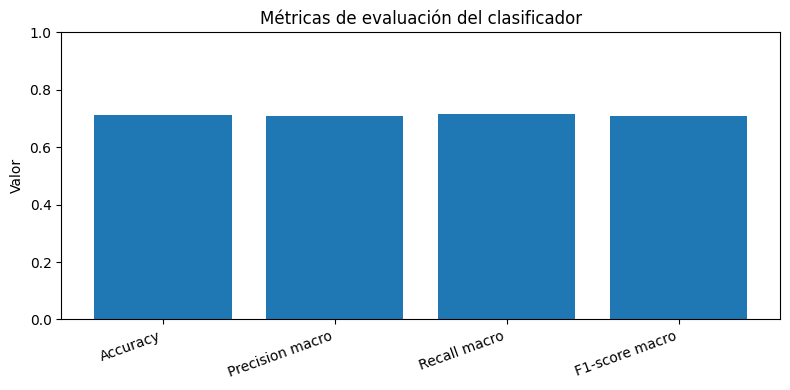

,Real,Predicha
No amistoso,58.76,52.52
Amistoso,41.24,47.48


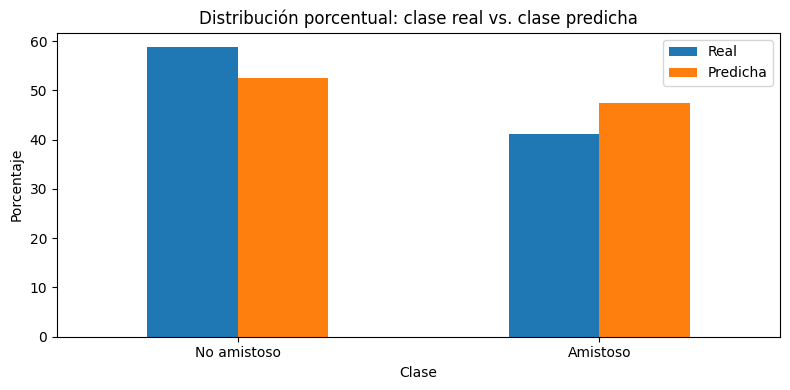

In [ ]:
# Gráfica comparativa de métricas
plt.figure(figsize=(8, 4))
plt.bar(metricas["Métrica"], metricas["Valor"])
plt.ylim(0, 1)
plt.ylabel("Valor")
plt.title("Métricas de evaluación del clasificador")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Comparación de clase real y predicha
comparacion = pd.DataFrame({
    "Real": y_test.value_counts(normalize=True),
    "Predicha": pd.Series(y_pred).value_counts(normalize=True)
}).fillna(0) * 100

display(comparacion.round(2))
comparacion.plot(kind="bar", figsize=(8, 4))
plt.title("Distribución porcentual: clase real vs. clase predicha")
plt.ylabel("Porcentaje")
plt.xlabel("Clase")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5.1 Interpretación de las métricas

- **Accuracy:** proporción total de predicciones correctas.
- **Precision macro:** promedio de la proporción de predicciones correctas entre las predicciones asignadas a cada clase.
- **Recall macro:** promedio de la proporción de casos de cada clase que el modelo logra identificar.
- **F1-score macro:** media armónica de precision y recall, promediada por clase.
- **Matriz de confusión:** las filas representan las clases reales y las columnas las clases predichas; la diagonal contiene aciertos y el resto son errores.

In [ ]:
# Línea base: predecir siempre la clase más frecuente del conjunto de entrenamiento.
clase_mayoritaria = y_train.value_counts().idxmax()
y_base = np.repeat(clase_mayoritaria, len(y_test))
accuracy_base = accuracy_score(y_test, y_base)

print(f"Accuracy del modelo: {accuracy:.4f}")
print(f"Accuracy de la línea base (clase mayoritaria): {accuracy_base:.4f}")

if accuracy > accuracy_base:
    print("El modelo supera la línea base en accuracy; revisa también las métricas por clase.")
elif np.isclose(accuracy, accuracy_base):
    print("El modelo iguala la línea base en accuracy; su utilidad predictiva puede ser limitada.")
else:
    print("El modelo no supera la línea base en accuracy; conviene revisar variables y estrategia.")

print("\\nLimitaciones a considerar:")
print("- La clase se deriva de tournament; esa columna se excluyó para evitar fuga directa.")
print("- Los equipos y la sede pueden no contener suficiente información para distinguir torneos.")
print("- El dataset puede abarcar periodos históricos con patrones distintos.")
print("- La división aleatoria no sustituye una validación temporal con partidos futuros.")
print("- El desempeño debe confirmarse con validación cruzada y datos recientes antes de cualquier uso real.")

Accuracy del modelo: 0.7121
Accuracy de la línea base (clase mayoritaria): 0.5876
El modelo supera la línea base en accuracy; revisa también las métricas por clase.
\nLimitaciones a considerar:
- La clase se deriva de tournament; esa columna se excluyó para evitar fuga directa.
- Los equipos y la sede pueden no contener suficiente información para distinguir torneos.
- El dataset puede abarcar periodos históricos con patrones distintos.
- La división aleatoria no sustituye una validación temporal con partidos futuros.
- El desempeño debe confirmarse con validación cruzada y datos recientes antes de cualquier uso real.


## Posibles mejoras

1. Incorporar variables que realmente estén disponibles antes del encuentro y tengan justificación para distinguir el tipo de partido.
2. Comparar Regresión Logística con árboles de decisión y Random Forest.
3. Evaluar con validación cruzada y una división temporal, entrenando con partidos antiguos y probando con partidos más recientes.
4. Revisar el balance de clases, los errores por categoría y la calidad de los datos.
5. Si se dispone de la competición prevista antes del encuentro, redefinir el objetivo del proyecto, porque usar la columna `tournament` como entrada sería prácticamente revelar la etiqueta.

**Nota de reproducibilidad:** los resultados exactos dependen de la versión del archivo `results.csv`. Ejecuta las celdas en orden para obtener las métricas y gráficas de tu conjunto de datos.

## Conclusión

El proyecto desarrolla las cinco fases de CRISP-DM: comprensión del negocio, comprensión de los datos, preparación, modelado y evaluación. Se construye una etiqueta binaria a partir del torneo, se preparan variables predictoras sin incluir la columna que define directamente la respuesta ni los goles posteriores al partido, y se entrena una Regresión Logística mediante un pipeline de Scikit-learn.
Las métricas obtenidas y la matriz de confusión permiten analizar su desempeño e identificar oportunidades de mejora para futuras implementaciones.